# THESAN-Zoom High Redshift Clump


## Introduction

This project is inspired by the observational finding that the high redshift clumps have lower metallicities than the host galaxy. (See https://ui.adsabs.harvard.edu/abs/2025ApJ...991..188E/abstract and https://ui.adsabs.harvard.edu/abs/2025ApJ...979...14S/abstract).

To see such behavior is also happening in the simulations, we started look at the THESAN-Zoom clump catalog produced by Zihao (See https://ui.adsabs.harvard.edu/abs/2025MNRAS.544.2675W/abstract).

But first, I need to understand what kind of data is saved in the catalog. So I started reading the THESAN-Zoom paper (Wang et al. 2025).

> We use CLOUDPHINDER (see D. Guszejnov et al. 2019 for its first application) to identify scattered regions within galaxies that are either actively forming stars or have the potential to do so. 

> First, in addition to gaseous structures, we incorporate young stars as an additional component of GMCs.

> Secondly, target gas cells must either have a number density exceeding 100 cm$^{−3}$ or a thermal Jeans length smaller than the cell size (consistent with the star formation criteria of the simulations).

> In addition, we limit the gas temperature to below 1000 K.

> To ensure that the identified GMCs are well resolved, we discard clouds that contain fewer than 30 elements, approximately corresponding to the number of gas cells within one gravitational softening length.




## Clump Catalog

I got the catalog from Zihao. And these are the contents in it.

> The GMC catalog is structured as follows:
> 
> 'GMC_alpha{}_n{}':  # records the setup of CloudPhinder
> 
>	Run: run identifiers (target galaxy, zoom factor), e.g., 'g39z4'
> 
>	HaloID: host group ID (central only)
> 
>	Snapshot: snapshot number
> 
>	CenterPosition: center of mass relative to the group center ['GroupPos'] # kpc
> 
>	EffectiveRadius # kpc
> 
>	GasMass # M_sun
> 
>	StellarMass # M_sun
> 
>	X_Fraction: mass-weighted gas metal fraction of element X
> 
>	X_Fraction_sfr: instantaneous-SFR-weighted gas metal fraction of X
> 
>	SFR_inst: instantaneous SFR # M_sun/yr
> 
>	SFR_yso:  3Myr-averaged SFR # M_sun/yr
> 
>	Number_of_Particles:	total number of component stellar particles or gaseous cell # Filter out unresolved GMC using > 30ish


Now I will read the catalog. I am not sure what HaloID means yet but I will figure it out. I might need a clump's distance from the group center (host galaxy). 

### Notes on the catalog (checked against the data)

The readme above is right except where noted. These points are verified in the files:

- **`z4`, `z8`, `z16` in run and file names are zoom factors (4×, 8×, 16× resolution), not redshifts.** `gmc_output.hdf5` is the 4× suite and spans z ≈ 15 → 3; `gmc_output_z16.hdf5` only covers z = 3.05–3.46. Redshift comes from the snapshot number (189 snapshots, z = 16 → 3, same grid for every run).
- **`HaloID` is the index of the FoF group in that snapshot's group catalog.** Groups are sorted by mass, so the index of a given galaxy changes over time: g205's main branch is *not* group 0 in 36 of 189 snapshots. Match clumps to the host with the tree's `Group_GroupID`, snapshot by snapshot.
- **`CenterPosition` is already relative to `GroupPos`**, in physical kpc. The clump's distance from the host centre is just its norm. `EffectiveRadius` is also physical kpc.
- **`SFR_yso` is stored as exactly `StellarMass / 3000`**, i.e. 1000 × the SFR in M⊙/yr. Divide by 1000. `SFR_inst` is already in M⊙/yr.
- **H and He are normalised separately from the metals**: `H_Fraction + He_Fraction ≈ 1 + Z`, so `1 - H - He` returns −Z. Build Z as the sum of C, N, O, Ne, Mg, Si, Fe.
- **`X_Fraction_sfr` is NaN** for clouds with no star-forming cell (about 40% of resolved 4× clouds).
- **Z⊙ = 0.0127** is used throughout, for clumps and host alike. It is the value of the THESAN/Illustris model and of the tree's `phys_*_Zsun` columns.
- **The catalog does not cover every snapshot.** For g205z4 there are no clouds at all at snapshots 0–24, 46–47, 63–66, 147 and 174–175 (174–175 have host SFR of 44–55 M⊙/yr, so they were not processed), and g205's own clouds appear mostly near SFR peaks. The paper selects starburst windows (§2.2), so this may be by design; to be confirmed with Zihao. See section 1b.
- **Only centrals are stored** (`HaloID: host group ID (central only)`). When the host is a satellite (e.g. g205 at snapshot 29, during a FoF bridge) its clouds are absent, so selections also require `Sub_SubhaloRankInGr == 0`.
- Resolved clouds have ≥ 30 elements. `tz_gmc.py` applies all of the above; `tz_gmc.load(..., resolved_only=True)` returns a table with physical units attached.


In [1]:
import os
import h5py
import glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import quad
from astropy import constants as const
from scipy.interpolate import interp1d
from scipy.stats import spearmanr

import tz_gmc

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
fname = "./gmc_catalog/gmc_output.hdf5"
group_name = "GMC_alpha20_n100"

In [3]:
with h5py.File(fname, "r") as f:
    g = f[group_name]
    print(f"Datasets in {group_name}:")
    for key in g.keys():
        print("  ", key, g[key].shape)

def load_gmc_catalog_df(filename, group_name):
    data = {}

    with h5py.File(filename, "r") as f:
        g = f[group_name]

        for key in g.keys():
            arr = g[key][()]

            # Decode byte strings
            if arr.dtype.kind in ["S", "O"]:
                arr = arr.astype(str)

            # Handle vector quantities (e.g. CenterPosition)
            if isinstance(arr, np.ndarray) and arr.ndim == 2:
                for i in range(arr.shape[1]):
                    data[f"{key}_{i}"] = arr[:, i]
            else:
                data[key] = arr

    return pd.DataFrame(data)

Datasets in GMC_alpha20_n100:
   C_Fraction (53651,)
   C_Fraction_sfr (53651,)
   CenterPosition (53651, 3)
   EffectiveRadius (53651,)
   Fe_Fraction (53651,)
   Fe_Fraction_sfr (53651,)
   GasMass (53651,)
   H_Fraction (53651,)
   H_Fraction_sfr (53651,)
   HaloID (53651,)
   He_Fraction (53651,)
   He_Fraction_sfr (53651,)
   Mg_Fraction (53651,)
   Mg_Fraction_sfr (53651,)
   N_Fraction (53651,)
   N_Fraction_sfr (53651,)
   Ne_Fraction (53651,)
   Ne_Fraction_sfr (53651,)
   Number_of_Particles (53651,)
   O_Fraction (53651,)
   O_Fraction_sfr (53651,)
   Run (53651,)
   SFR_inst (53651,)
   SFR_yso (53651,)
   Si_Fraction (53651,)
   Si_Fraction_sfr (53651,)
   Snapshot (53651,)
   StellarMass (53651,)
   VirialParameter (53651,)


In [4]:
df = load_gmc_catalog_df(fname, group_name)

Z = (
    df["C_Fraction"] +
    df["N_Fraction"] +
    df["O_Fraction"] +
    df["Ne_Fraction"] +
    df["Mg_Fraction"] +
    df["Si_Fraction"] +
    df["Fe_Fraction"]
)

Z_sfr = (
    df["C_Fraction_sfr"] +
    df["N_Fraction_sfr"] +
    df["O_Fraction_sfr"] +
    df["Ne_Fraction_sfr"] +
    df["Mg_Fraction_sfr"] +
    df["Si_Fraction_sfr"] +
    df["Fe_Fraction_sfr"]
)

df["Z"] = Z
df["Z_sfr"] = Z_sfr

In [5]:
df_g39z4 = df.query("Run == 'g39z4'")

In [6]:
with pd.option_context('display.max_columns', None):
    display(df_g39z4.dropna())

,C_Fraction,C_Fraction_sfr,CenterPosition_0,CenterPosition_1,CenterPosition_2,EffectiveRadius,Fe_Fraction,Fe_Fraction_sfr,GasMass,H_Fraction,H_Fraction_sfr,HaloID,He_Fraction,He_Fraction_sfr,Mg_Fraction,Mg_Fraction_sfr,N_Fraction,N_Fraction_sfr,Ne_Fraction,Ne_Fraction_sfr,Number_of_Particles,O_Fraction,O_Fraction_sfr,Run,SFR_inst,SFR_yso,Si_Fraction,Si_Fraction_sfr,Snapshot,StellarMass,VirialParameter,Z,Z_sfr
34992,0.000006,0.000007,-0.184062,0.566459,0.476218,0.052659,6.950784e-07,7.271732e-07,2.007278e+06,0.760000,0.760000,1,0.240089,0.240097,9.730603e-07,9.814299e-07,1.413037e-07,1.458578e-07,0.000008,0.000009,184,0.000076,0.000080,g39z4,0.020121,28.486875,0.000001,0.000001,2,8.546062e+04,6.152065,0.000093,0.000098
35009,0.000007,0.000006,0.017479,-0.088206,-0.043080,0.018102,1.896373e-06,1.365305e-06,4.125724e+05,0.759993,0.759994,1,0.240097,0.240085,1.083714e-06,9.736416e-07,1.217099e-06,9.653249e-07,0.000008,0.000007,37,0.000068,0.000064,g39z4,0.028144,0.000000,0.000002,0.000002,4,0.000000e+00,1.385422,0.000089,0.000082
35012,0.000007,0.000007,0.092010,-0.117780,-0.044620,0.007174,1.434672e-06,1.324554e-06,1.128630e+05,0.759995,0.759996,1,0.240102,0.240099,1.177645e-06,1.148631e-06,9.851098e-07,9.193495e-07,0.000009,0.000008,10,0.000076,0.000075,g39z4,0.015795,0.000000,0.000002,0.000002,4,0.000000e+00,1.580049,0.000098,0.000095
35014,0.000024,0.000020,0.054862,-0.029599,0.006829,0.094020,7.324085e-06,6.143372e-06,8.089367e+06,0.759997,0.759998,1,0.240277,0.240253,4.232591e-06,3.390156e-06,1.628227e-06,1.451124e-06,0.000025,0.000023,838,0.000234,0.000212,g39z4,0.680846,386.427000,0.000008,0.000006,5,1.159281e+06,7.374960,0.000304,0.000272
35015,0.000031,0.000035,-0.084783,-0.021542,-0.171264,0.068049,9.310994e-06,1.024245e-05,5.710924e+06,0.759997,0.759997,1,0.240323,0.240356,5.829732e-06,6.394697e-06,1.741627e-06,1.984549e-06,0.000030,0.000034,560,0.000289,0.000331,g39z4,0.160984,164.261500,0.000011,0.000013,5,4.927845e+05,11.300545,0.000378,0.000431
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53640,0.004109,0.004189,-5.295923,0.975025,1.254781,0.011309,1.160207e-03,1.191197e-03,3.950657e+04,0.758490,0.758490,0,0.258931,0.258944,2.457635e-04,2.501768e-04,7.373588e-04,7.377267e-04,0.001122,0.001123,5,0.008759,0.008826,g39z4,0.007358,9.363462,0.000896,0.000916,186,2.809039e+04,2.980792,0.017029,0.017233
53643,0.001706,0.001702,0.448435,0.034709,-0.313144,0.005565,4.229194e-04,4.216491e-04,3.818154e+04,0.759196,0.759195,0,0.250077,0.250081,1.070701e-04,1.067454e-04,4.160856e-04,4.163023e-04,0.000637,0.000637,6,0.003855,0.003848,g39z4,0.054751,7.724035,0.000317,0.000316,186,2.317211e+04,17.549197,0.007461,0.007448
53644,0.002396,0.002373,0.262830,0.916088,0.299264,0.006447,6.119582e-04,6.056654e-04,6.056641e+04,0.758631,0.758631,0,0.256290,0.256292,1.302060e-04,1.288344e-04,7.390152e-04,7.390775e-04,0.000958,0.000958,4,0.005140,0.005104,g39z4,0.053866,0.000000,0.000441,0.000437,186,0.000000e+00,7.400037,0.010416,0.010345
53646,0.003323,0.003305,-3.242712,-5.574090,-1.904025,0.014693,7.525253e-04,7.484799e-04,5.797148e+04,0.759037,0.759036,0,0.253418,0.253403,1.918409e-04,1.907712e-04,5.371123e-04,5.372408e-04,0.000852,0.000851,4,0.006697,0.006677,g39z4,0.013735,0.000000,0.000596,0.000592,186,0.000000e+00,16.625380,0.012951,0.012902


12146

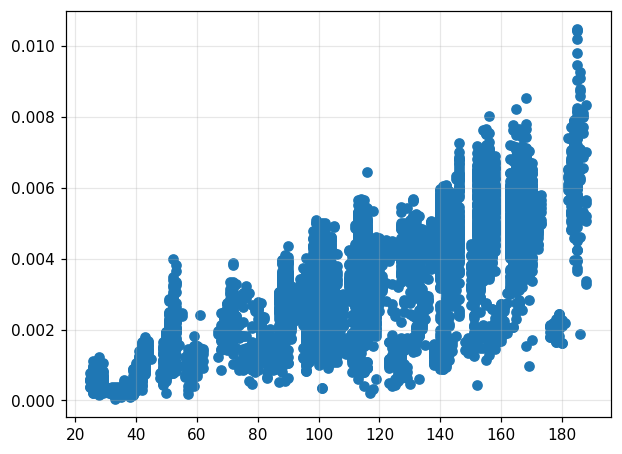

In [7]:
df_target = df.query("Run == 'g205z4'") #df_g39z4 g205z4
plt.scatter(df_target["Snapshot"],df_target["Z"])
len(df_target)

In [8]:
# HaloID is a per-snapshot index, not a fixed label, so "HaloID == 0" picks up a
# different halo whenever g205 is not the most massive group. Match the main
# branch from the tree instead, keep only snapshots where the host is the
# central of its group (the catalog stores centrals only), and drop
# unresolved clouds (< 30 elements).
tree_g205 = pd.read_csv("g205_z4_host_halo.csv")
main_gid = dict(zip(tree_g205["snap"].astype(int), tree_g205["Group_GroupID"].astype(int)))
central = dict(zip(tree_g205["snap"].astype(int), tree_g205["Sub_SubhaloRankInGr"] == 0))

df_target = df_target[(df_target["HaloID"] == df_target["Snapshot"].map(main_gid))
                      & df_target["Snapshot"].map(central)
                      & (df_target["Number_of_Particles"] >= 30)]
df_target

,C_Fraction,C_Fraction_sfr,CenterPosition_0,CenterPosition_1,CenterPosition_2,EffectiveRadius,Fe_Fraction,Fe_Fraction_sfr,GasMass,H_Fraction,...,Run,SFR_inst,SFR_yso,Si_Fraction,Si_Fraction_sfr,Snapshot,StellarMass,VirialParameter,Z,Z_sfr
22846,0.000052,0.000049,0.176503,0.094493,-0.140167,0.031342,0.000028,0.000027,6.332619e+05,0.759946,...,g205z4,0.028924,9.850250,0.000022,0.000021,25,29550.7500,12.544486,0.000573,0.000554
22847,0.000052,0.000050,0.245519,0.309483,-0.273756,0.021461,0.000026,0.000025,5.926812e+05,0.759953,...,g205z4,0.028472,19.209979,0.000022,0.000021,25,57629.9375,5.219874,0.000592,0.000583
22850,0.000080,0.000067,0.013190,0.005155,0.001589,0.066816,0.000036,0.000030,3.022677e+06,0.759941,...,g205z4,0.431601,284.963667,0.000029,0.000024,26,854891.0000,17.599156,0.000833,0.000782
22851,0.000059,0.000055,0.140363,-0.059618,0.051951,0.050459,0.000027,0.000024,2.093149e+06,0.759959,...,g205z4,0.264651,104.914750,0.000023,0.000021,26,314744.2500,9.010038,0.000645,0.000640
22852,0.000088,0.000088,0.040646,-0.041581,0.260706,0.036060,0.000040,0.000040,9.939436e+05,0.759937,...,g205z4,0.086504,5.617250,0.000033,0.000033,26,16851.7500,3.082915,0.000926,0.000934
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34946,0.000984,0.000881,-1.558052,-0.132754,-0.523150,0.024747,0.000326,0.000303,4.555646e+05,0.759567,...,g205z4,0.010995,0.000000,0.000219,0.000205,158,0.0000,9.949676,0.004955,0.004730
34947,0.001026,0.000813,-1.925177,-0.438573,-0.351041,0.022643,0.000328,0.000271,3.941194e+05,0.759512,...,g205z4,0.053989,12.317542,0.000220,0.000186,158,36952.6250,4.764850,0.005288,0.004834
34948,0.001220,NaN,-1.514287,-0.278039,0.499445,0.025830,0.000369,NaN,3.310916e+05,0.759474,...,g205z4,0.000000,22.149083,0.000246,NaN,158,66447.2500,18.414500,0.005955,NaN
34949,0.001144,NaN,-2.204168,-0.450865,-0.069576,0.018690,0.000381,NaN,3.804337e+05,0.759515,...,g205z4,0.000000,0.000000,0.000253,NaN,158,0.0000,3.385791,0.005545,NaN


clumps with SFR_inst = 0 (not shown): 938 of 4189


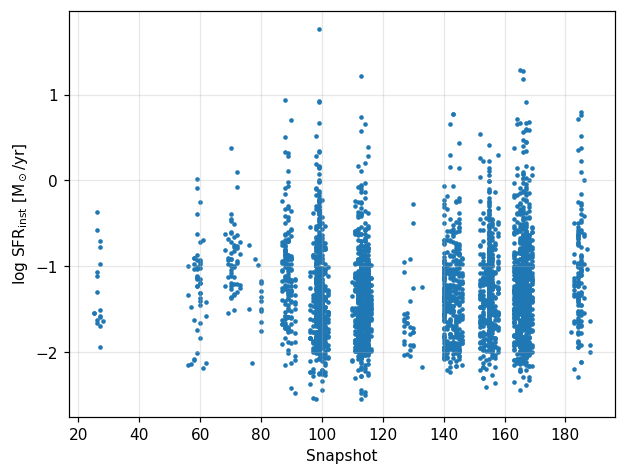

In [9]:
# log10(0) = -inf is dropped silently by matplotlib, so count the zeros explicitly
sf = df_target["SFR_inst"] > 0
plt.scatter(df_target.loc[sf, "Snapshot"], np.log10(df_target.loc[sf, "SFR_inst"]), s=4)
plt.xlabel("Snapshot")
plt.ylabel(r"log SFR$_{\rm inst}$ [M$_\odot$/yr]")
print("clumps with SFR_inst = 0 (not shown): %d of %d" % ((~sf).sum(), len(sf)))

clumps with StellarMass = 0 (not shown): 716 of 4189


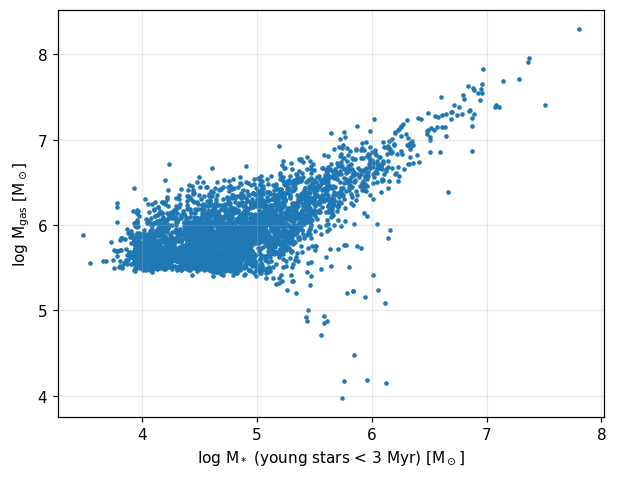

In [10]:
has_stars = df_target["StellarMass"] > 0
plt.scatter(np.log10(df_target.loc[has_stars, "StellarMass"]),
            np.log10(df_target.loc[has_stars, "GasMass"]), s=4)
plt.xlabel(r"log M$_*$ (young stars < 3 Myr) [M$_\odot$]")
plt.ylabel(r"log M$_{\rm gas}$ [M$_\odot$]")
print("clumps with StellarMass = 0 (not shown): %d of %d" % ((~has_stars).sum(), len(has_stars)))

---

## 1. Attaching the host galaxy

The catalog contains clouds only; there is no row for the host galaxy. So the host metallicity cannot come from the clumps: the mean over a galaxy's clumps makes ΔZ zero by construction, and the clump with the most stars is still just a clump. The host value has to come from the host's own subhalo in the main-progenitor tree.

Locally only g205 has a tree (`g205_z4_host_halo.csv`). For other targets, run `tz_tree_catalog.py` on ORCD and save the output here as `<target>_z<zoom>_host_halo.csv` (e.g. `g578_z4_host_halo.csv`); the cells below pick up every such file automatically.

The tree offers several host apertures, and the answer depends on which one you compare to:

| key | tree field | what it measures |
|---|---|---|
| `all` | `SubhaloGasMetalFractions` | mass-weighted over all gas bound to the central subhalo, including the CGM |
| `halfrad` | `…HalfRad` | mass-weighted, gas within the stellar half-mass radius |
| `sf` | `…Sfr` | mass-weighted over star-forming cells only |
| `sfrw` | `…SfrWeighted` | SFR-weighted over all cells; the closest analogue of an emission-line host value |
| `sfrw_out` | derived below | SFR-weighted, after removing the resolved clumps' own contribution: the star-forming gas *outside* the clumps |


In [11]:
ZSUN = tz_gmc.ZSUN                       # 0.0127, used for clumps and host alike
A_O, A_H = 15.999, 1.008
GFM = {"H": 0, "He": 1, "C": 2, "N": 3, "O": 4, "Ne": 5, "Mg": 6, "Si": 7, "Fe": 8}
METALS = ["C", "N", "O", "Ne", "Mg", "Si", "Fe"]
APERTURES = {"all": "", "halfrad": "HalfRad", "sf": "Sfr", "sfrw": "SfrWeighted"}


def oh12(xo, xh):
    """12 + log(O/H) by number from O and H mass fractions; NaN where undefined."""
    xo, xh = np.asarray(xo, float), np.asarray(xh, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        v = 12 + np.log10((xo / A_O) / (xh / A_H))
    return np.where(np.isfinite(v), v, np.nan)


def load_host(path):
    """One row per snapshot: the main-branch host's metallicity in each aperture."""
    t = pd.read_csv(path)
    out = pd.DataFrame({"Snapshot": t["snap"].astype(int),
                        "GroupID": t["Group_GroupID"].astype(int),
                        "R200": t["phys_Group_Group_R_Crit200_kpc"],
                        "rank": t["Sub_SubhaloRankInGr"].astype(int),
                        "host_SFR": t["Sub_SubhaloSFR"],
                        "group_SFR": t["Group_GroupSFR"],
                        "host_Mgas": t["phys_Sub_SubhaloMassType_0_Msun"],
                        "z_host": t["Redshift"]})
    for key, suf in APERTURES.items():
        x = {e: t[f"Sub_SubhaloGasMetalFractions{suf}_{i}"].to_numpy(float) for e, i in GFM.items()}
        xz = sum(x[e] for e in METALS)
        bad = xz <= 0                    # SFR-based apertures are 0 when the host has no SFR
        out[f"Z_{key}"] = np.where(bad, np.nan, xz / ZSUN)
        out[f"OH_{key}"] = np.where(bad, np.nan, oh12(x["O"], x["H"]))
        if key == "sfrw":                # kept to subtract the clumps' share later
            out["XO_sfrw"], out["XH_sfrw"], out["XZ_sfrw"] = x["O"], x["H"], xz
    return out


hosts = {}
for path in sorted(glob.glob("*_host_halo.csv")):
    target, zoom = os.path.basename(path).replace("_host_halo.csv", "").split("_")
    hosts[target + zoom] = load_host(path)
print("runs with a host tree:", list(hosts))

runs with a host tree: ['g205z4']


## 1b. Does the catalog's `HaloID` point to the same galaxy as the tree?

Everything below assumes that clouds with `HaloID == Group_GroupID` belong to the host described by the tree. Both numbers are documented as the index of a FoF group in that snapshot's `fof_subhalo_tab` (catalog readme; `tz_tree_catalog.py`), and the paper's sample is the central galaxies, i.e. the main SUBFIND-HBT subhalo of each group (Wang et al. 2025, §2.2). That does not prove the catalog was built from the same group files as the tree, so these tests check it in the data. They use every cloud, including unresolved ones, which is the strictest version.

1. **Conservation.** `SFR_inst` and `GasMass` are sums over gas cells, so a galaxy's clouds can never carry more SFR or gas than the galaxy. Clouds of a *different* galaxy have no such limit.
2. **Reshuffled snapshots.** Where the host is not group 0, the tree's `GroupID` and `HaloID == 0` point to different groups. Only the right one can satisfy test 1.
3. **Time tracking.** The host SFR is bursty; its own clouds' summed SFR should follow it snapshot by snapshot.
4. **Satellite snapshots.** Where the host is not the central of its group (`rank != 0`), the catalog should hold no clouds for it.
5. **Coverage.** Which snapshots have clouds at all, for any halo in the run, and for the host.


In [12]:
allclouds = tz_gmc.load(variant="fiducial")      # every cloud, unresolved included


def host_match_table(run, host):
    """One row per (snapshot, HaloID) with the clouds' totals relative to the tree host."""
    h = host.set_index("Snapshot")
    cl = allclouds[allclouds["Run"] == run]
    per = (cl.groupby(["Snapshot", "HaloID"])
             .agg(N=("sfr_inst", "size"), SFR=("sfr_inst", "sum"), Mgas=("M_gas", "sum"), Z=("Z_Zsun", "median"))
             .reset_index())
    s = per["Snapshot"]
    per["tree_gid"] = s.map(h["GroupID"])
    per["rank"] = s.map(h["rank"])
    per["matched"] = per["HaloID"] == per["tree_gid"]
    with np.errstate(divide="ignore", invalid="ignore"):
        per["r_SFR"] = (per["SFR"] / s.map(h["host_SFR"])).replace(np.inf, np.nan)
        per["r_SFR_group"] = (per["SFR"] / s.map(h["group_SFR"])).replace(np.inf, np.nan)
        per["r_Mgas"] = per["Mgas"] / s.map(h["host_Mgas"])
        per["r_Z"] = per["Z"] / s.map(h["Z_all"])
    return per


summary, tables = [], {}
for run, host in hosts.items():
    per = host_match_table(run, host)
    tables[run] = per
    h = host.set_index("Snapshot")
    yes = per[per["matched"] & (per["rank"] == 0)]
    no = per[~per["matched"]]
    reshuffled = per["Snapshot"].isin(h.index[h["GroupID"] != 0])
    m_rs, z_rs = per[reshuffled & per["matched"]], per[reshuffled & ~per["matched"] & (per["HaloID"] == 0)]
    tr_yes, tr_no = yes[(yes["SFR"] > 0) & yes["r_SFR"].notna()], no[(no["SFR"] > 0) & no["r_SFR"].notna()]
    sat = per[per["matched"] & (per["rank"] != 0)]
    summary.append({
        "run": run,
        # test 1
        "matched pairs": len(yes),
        "matched: max sum Mgas / host": yes["r_Mgas"].max(),
        "matched: pairs SFR > host": int((yes["r_SFR"] > 1.0001).sum()),
        "matched: max SFR / host": yes["r_SFR"].max(),
        "matched: pairs SFR > group": int((yes["r_SFR_group"] > 1.0001).sum()),
        "other: pairs SFR > host": int((no["r_SFR"] > 1.0001).sum()),
        "other: max SFR / host": no["r_SFR"].max(),
        # test 2
        "reshuffled: matched max SFR / host": m_rs["r_SFR"].max(),
        "reshuffled: HaloID 0 max SFR / host": z_rs["r_SFR"].max(),
        "reshuffled: matched median Z ratio": m_rs["r_Z"].median(),
        # test 3
        "tracking rho, matched": spearmanr(tr_yes["SFR"], tr_yes["Snapshot"].map(h["host_SFR"]))[0],
        "tracking rho, other": spearmanr(tr_no["SFR"], tr_no["Snapshot"].map(h["host_SFR"]))[0],
        # test 4
        "satellite snapshots with host clouds": int(sat["Snapshot"].nunique()),
    })

pd.set_option("display.max_colwidth", 60)
pd.DataFrame(summary).set_index("run").T.round(3)

run,g205z4
matched pairs,79.000
matched: max sum Mgas / host,0.016
matched: pairs SFR > host,2.000
matched: max SFR / host,1.100
matched: pairs SFR > group,0.000
other: pairs SFR > host,35.000
other: max SFR / host,47.293
reshuffled: matched max SFR / host,0.823
reshuffled: HaloID 0 max SFR / host,47.293
reshuffled: matched median Z ratio,1.023


In [13]:
# Pass/fail against the expectations stated above. A violation of the host
# limit that stays within the group limit means the clouds include group gas
# not bound to the central subhalo -- noted, not a mismatch.
for row in summary:
    run = row["run"]
    per = tables[run]
    yes = per[per["matched"] & (per["rank"] == 0)]
    checks = {
        "1. matched clouds never exceed the group's SFR or the host's gas":
            row["matched: pairs SFR > group"] == 0 and row["matched: max sum Mgas / host"] <= 1,
        "1. some other HaloIDs exceed the host (they are other galaxies)":
            row["other: pairs SFR > host"] > 0,
        "2. in reshuffled snapshots the tree's GroupID passes the host limit":
            not (row["reshuffled: matched max SFR / host"] > 1.0001),
        "3. matched clouds track the host SFR (rho > 0.8), others do not (rho < 0.5)":
            row["tracking rho, matched"] > 0.8 and row["tracking rho, other"] < 0.5,
        "4. no host clouds while the host is a satellite":
            row["satellite snapshots with host clouds"] == 0,
    }
    print(run)
    for name, ok in checks.items():
        print("   %s  %s" % ("PASS" if ok else "CHECK", name))
    over = yes[yes["r_SFR"] > 1.0001]
    if len(over):
        print("   note: clouds exceed SubhaloSFR (but not GroupSFR) at snapshots",
              ", ".join("%d (x%.2f)" % (s, r) for s, r in zip(over["Snapshot"], over["r_SFR"])),
              "-> clouds include some group gas outside the central subhalo")

g205z4
   PASS  1. matched clouds never exceed the group's SFR or the host's gas
   PASS  1. some other HaloIDs exceed the host (they are other galaxies)
   PASS  2. in reshuffled snapshots the tree's GroupID passes the host limit
   PASS  3. matched clouds track the host SFR (rho > 0.8), others do not (rho < 0.5)
   PASS  4. no host clouds while the host is a satellite
   note: clouds exceed SubhaloSFR (but not GroupSFR) at snapshots 98 (x1.01), 99 (x1.10) -> clouds include some group gas outside the central subhalo


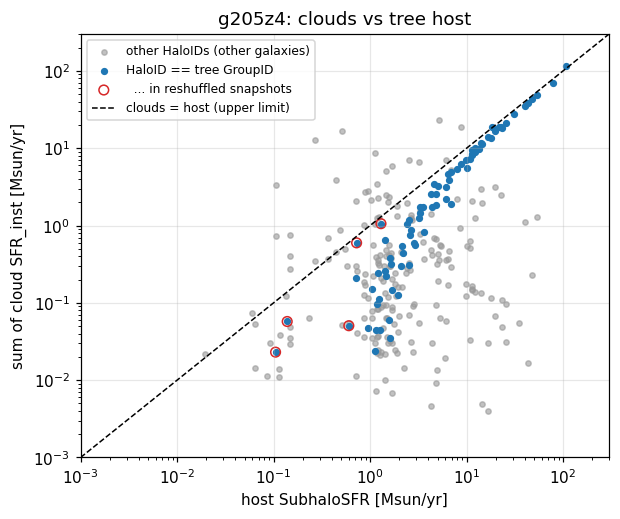

In [14]:
# Test 1-3 in one picture: clouds' summed SFR against the host's SFR, per (snapshot, HaloID).
fig, axes = plt.subplots(1, len(tables), figsize=(6.2 * len(tables), 5), squeeze=False)
for ax, (run, per) in zip(axes[0], tables.items()):
    h = hosts[run].set_index("Snapshot")
    p = per[per["SFR"] > 0].copy()
    p["host_SFR"] = p["Snapshot"].map(h["host_SFR"])
    p = p[p["host_SFR"] > 0]
    other = p[~p["matched"]]
    good = p[p["matched"] & (p["rank"] == 0)]
    ax.scatter(other["host_SFR"], other["SFR"], s=12, c="0.6", alpha=0.6, label="other HaloIDs (other galaxies)")
    ax.scatter(good["host_SFR"], good["SFR"], s=14, c="C0", label="HaloID == tree GroupID")
    rs = good["Snapshot"].isin(h.index[h["GroupID"] != 0])
    ax.scatter(good.loc[rs, "host_SFR"], good.loc[rs, "SFR"], s=40, facecolors="none", edgecolors="C3",
               label="  ... in reshuffled snapshots")
    lim = [1e-3, 3e2]
    ax.plot(lim, lim, "k--", lw=1, label="clouds = host (upper limit)")
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="host SubhaloSFR [Msun/yr]",
           ylabel="sum of cloud SFR_inst [Msun/yr]", title=f"{run}: clouds vs tree host")
    ax.legend(fontsize=8, loc="upper left")
plt.show()

In [15]:
# Test 5: which snapshots have clouds at all?
for run, host in hosts.items():
    h = host.set_index("Snapshot")
    snaps_any = set(allclouds.loc[allclouds["Run"] == run, "Snapshot"])
    snaps_host = set(tables[run].loc[tables[run]["matched"] & (tables[run]["rank"] == 0), "Snapshot"])
    missing = sorted(set(h.index) - snaps_any)
    blocks, start = [], None
    for s in missing:
        if start is None or s != prev + 1:
            if start is not None:
                blocks.append((start, prev))
            start = s
        prev = s
    if start is not None:
        blocks.append((start, prev))
    print(run)
    print("  snapshots with clouds for any halo: %d of %d;  with host clouds: %d"
          % (len(snaps_any), len(h), len(snaps_host)))
    print("  no clouds at all at snapshots:", ", ".join(f"{a}-{b}" if a != b else f"{a}" for a, b in blocks))
    busy = h.loc[[s for s in missing if h.loc[s, "host_SFR"] > 1], ["z_host", "host_SFR"]]
    if len(busy):
        print("  ...of which the host had SFR > 1 Msun/yr (so not physically cloud-free):")
        print("  " + busy.round(2).to_string().replace("\n", "\n  "))
    proc = h.loc[sorted(snaps_any)]
    has = proc.index.isin(snaps_host)
    print("  processed snapshots, host SFR median: with host clouds %.2f, without %.2f Msun/yr"
          % (proc.loc[has, "host_SFR"].median(), proc.loc[~has, "host_SFR"].median()))

g205z4
  snapshots with clouds for any halo: 155 of 189;  with host clouds: 79
  no clouds at all at snapshots: 0-24, 46-47, 63-66, 147, 174-175
  ...of which the host had SFR > 1 Msun/yr (so not physically cloud-free):
            z_host  host_SFR
  Snapshot                  
  63          6.28      1.41
  65          6.16      1.12
  66          6.11      1.28
  147         3.64      5.35
  174         3.21     44.29
  175         3.19     55.27
  processed snapshots, host SFR median: with host clouds 4.30, without 1.37 Msun/yr


## 2. Clump sample

4× fiducial clouds, resolved (≥ 30 elements), in the main-branch host group of each run that has a tree, at snapshots where the host is the central of its group (section 1b). Two clump metallicities:

- `Z_Zsun`, `OH`: mass-weighted over the cloud's gas (every resolved clump has one)
- `Z_sfr`, `OH_sfr`: SFR-weighted, defined only for star-forming clumps. This is the analogue of an emission-line clump measurement.


In [16]:
cat = tz_gmc.load(res=4, variant="fiducial", resolved_only=True)
cat["OH"] = oh12(cat["O_Fraction"], cat["H_Fraction"])
cat["OH_sfr"] = oh12(cat["O_Fraction_sfr"], cat["H_Fraction_sfr"])
cat["Z_sfr_Zsun"] = cat["Z_sfr"] / ZSUN

parts = []
for run, host in hosts.items():
    c = cat[cat["Run"] == run].merge(host, on="Snapshot")
    parts.append(c[(c["HaloID"] == c["GroupID"]) & (c["rank"] == 0)])   # main branch, host is central
clumps = pd.concat(parts, ignore_index=True)
clumps["x"] = clumps["d_center_kpc"] / clumps["R200"]
clumps["star_forming"] = clumps["sfr_inst"] > 0

print("%d resolved main-branch clumps, %d star-forming, in %d snapshots (z = %.2f - %.2f)"
      % (len(clumps), clumps["star_forming"].sum(), clumps[["Run", "Snapshot"]].drop_duplicates().shape[0],
         clumps["z"].min(), clumps["z"].max()))
print("checks: Z range %.3f - %.3f Zsun, distance %.2f - %.1f kpc, 12+log(O/H) %.2f - %.2f"
      % (clumps["Z_Zsun"].min(), clumps["Z_Zsun"].max(), clumps["d_center_kpc"].min(),
         clumps["d_center_kpc"].max(), clumps["OH"].min(), clumps["OH"].max()))

4189 resolved main-branch clumps, 3251 star-forming, in 76 snapshots (z = 3.01 - 9.64)
checks: Z range 0.014 - 0.823 Zsun, distance 0.01 - 36.7 kpc, 12+log(O/H) 7.01 - 8.63


## 3. Clump vs host, one value per snapshot

Clumps in the same snapshot share one gas reservoir, so they are not independent measurements. Each snapshot is summarised by its median clump, and scatter is quoted across snapshots.

The `sfrw_out` host removes the resolved clumps from the host's SFR-weighted average:

X_out = (SFR_host · X_host,sfrw − Σ SFR_clump · X_clump,sfr) / (SFR_host − Σ SFR_clump).

This assumes the clumps' cells are part of the central subhalo. It is left undefined where the resolved clumps carry more than 90% of the host SFR, since the remainder is then too small to measure.


In [17]:
def per_snapshot(c):
    sf = c["star_forming"]
    w = c.loc[sf, "sfr_inst"]
    return pd.Series({
        "z": c["z"].iloc[0], "N": len(c), "N_sf": int(sf.sum()),
        "Z_clump": c["Z_Zsun"].median(),
        "Z_clump_sfr": c.loc[sf, "Z_sfr_Zsun"].median(),
        "OH_clump": c["OH"].median(),
        "OH_clump_sfr": c.loc[sf, "OH_sfr"].median(),
        "SFR_clumps": w.sum(),
        "XO_cl": (w * c.loc[sf, "O_Fraction_sfr"]).sum(),
        "XH_cl": (w * c.loc[sf, "H_Fraction_sfr"]).sum(),
        "XZ_cl": (w * c.loc[sf, "Z_sfr"]).sum()})


host_all = pd.concat([h.assign(Run=r) for r, h in hosts.items()]).set_index(["Run", "Snapshot"])
snaps = (clumps.groupby(["Run", "Snapshot"]).apply(per_snapshot, include_groups=False)
         .join(host_all))

# host star formation outside the resolved clumps
snaps["f_clump_SFR"] = snaps["SFR_clumps"] / snaps["host_SFR"]
ok = (snaps["host_SFR"] > 0) & (snaps["f_clump_SFR"] < 0.9)
rest = snaps["host_SFR"] - snaps["SFR_clumps"]
xo = (snaps["host_SFR"] * snaps["XO_sfrw"] - snaps["XO_cl"]) / rest
xh = (snaps["host_SFR"] * snaps["XH_sfrw"] - snaps["XH_cl"]) / rest
xz = (snaps["host_SFR"] * snaps["XZ_sfrw"] - snaps["XZ_cl"]) / rest
snaps["OH_sfrw_out"] = np.where(ok, oh12(xo, xh), np.nan)
snaps["Z_sfrw_out"] = np.where(ok & (xz > 0), xz / ZSUN, np.nan)

# offsets in dex. Mass-weighted clumps are compared to the mass-weighted
# apertures; SFR-weighted clumps to the SFR-based ones.
for key in ["all", "halfrad", "sf"]:
    snaps[f"dlogZ_{key}"] = np.log10(snaps["Z_clump"] / snaps[f"Z_{key}"])
    snaps[f"dOH_{key}"] = snaps["OH_clump"] - snaps[f"OH_{key}"]
for key in ["sfrw", "sfrw_out"]:
    snaps[f"dlogZ_{key}"] = np.log10(snaps["Z_clump_sfr"] / snaps[f"Z_{key}"])
    snaps[f"dOH_{key}"] = snaps["OH_clump_sfr"] - snaps[f"OH_{key}"]

print("snapshots: %d;  with a defined 'outside clumps' host: %d"
      % (len(snaps), snaps["OH_sfrw_out"].notna().sum()))
print("share of host SFR in resolved clumps: median %.2f (16-84%%: %.2f - %.2f)"
      % tuple(snaps["f_clump_SFR"].quantile([0.5, 0.16, 0.84])))

snapshots: 76;  with a defined 'outside clumps' host: 74
share of host SFR in resolved clumps: median 0.47 (16-84%: 0.10 - 0.81)


In [18]:
HOSTS = ["all", "halfrad", "sf", "sfrw", "sfrw_out"]


def summarise(col):
    s = snaps[col].dropna()
    return "%+.3f  [%+.3f, %+.3f]  n=%d" % (s.median(), s.quantile(0.16), s.quantile(0.84), len(s))


print("Delta 12+log(O/H) = clump - host, dex; median [16th, 84th] over snapshots\n")
for key in HOSTS:
    print("  host = %-9s %s" % (key, summarise(f"dOH_{key}")))

zbins = [3, 3.5, 4, 5, 6, 8, 10]
table = snaps.groupby(pd.cut(snaps["z"], zbins), observed=True)[[f"dOH_{k}" for k in HOSTS]].median()
table.insert(0, "snapshots", snaps.groupby(pd.cut(snaps["z"], zbins), observed=True).size())
table.round(3)

Delta 12+log(O/H) = clump - host, dex; median [16th, 84th] over snapshots

  host = all       +0.002  [-0.054, +0.064]  n=76
  host = halfrad   -0.016  [-0.068, +0.019]  n=76
  host = sf        +0.043  [-0.012, +0.078]  n=76
  host = sfrw      +0.033  [-0.009, +0.063]  n=74
  host = sfrw_out  +0.012  [-0.018, +0.063]  n=72


,snapshots,dOH_all,dOH_halfrad,dOH_sf,dOH_sfrw,dOH_sfrw_out
z,,,,,,
"(3.0, 3.5]",18,-0.002,-0.025,0.076,0.059,0.019
"(3.5, 4.0]",14,-0.009,-0.025,0.063,0.034,0.018
"(4.0, 5.0]",17,0.013,-0.003,0.024,0.014,0.008
"(5.0, 6.0]",15,0.056,-0.010,0.051,0.037,0.035
"(6.0, 8.0]",8,-0.050,-0.023,-0.036,-0.027,-0.029
"(8.0, 10.0]",4,0.012,-0.054,0.065,0.055,0.114


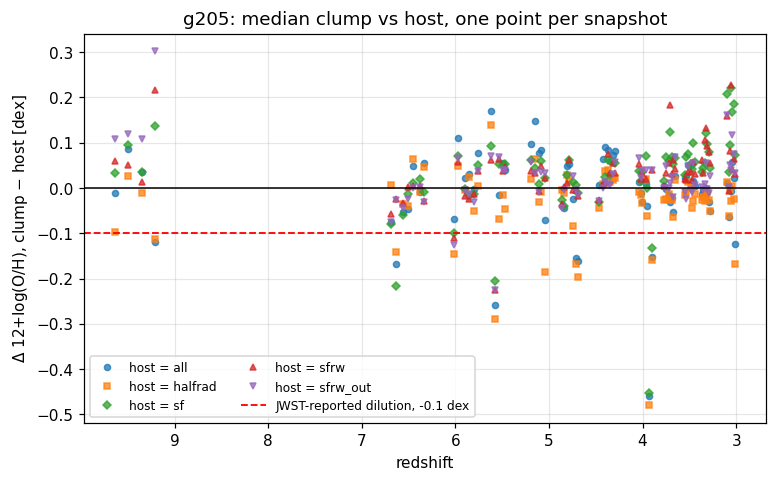

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for key, mk in zip(HOSTS, "osD^v"):
    ax.plot(snaps["z"], snaps[f"dOH_{key}"], mk, ms=4, alpha=0.75, label=f"host = {key}")
ax.axhline(0, color="k", lw=1)
ax.axhline(-0.1, color="r", ls="--", lw=1.2, label="JWST-reported dilution, -0.1 dex")
ax.invert_xaxis()
ax.set_xlabel("redshift")
ax.set_ylabel(r"$\Delta$ 12+log(O/H), clump $-$ host [dex]")
ax.set_title("g205: median clump vs host, one point per snapshot")
ax.legend(fontsize=8, ncol=2)
plt.show()

## 4. Clump vs host metallicity plane

Same axes as the earlier Figure 6 attempt (host log Z on x, clump log Z on y), but with the host taken from the tree at the clump's own snapshot, and colour showing redshift. Left: mass-weighted clumps against all host gas. Right: SFR-weighted star-forming clumps against the host's star-forming gas outside the clumps.


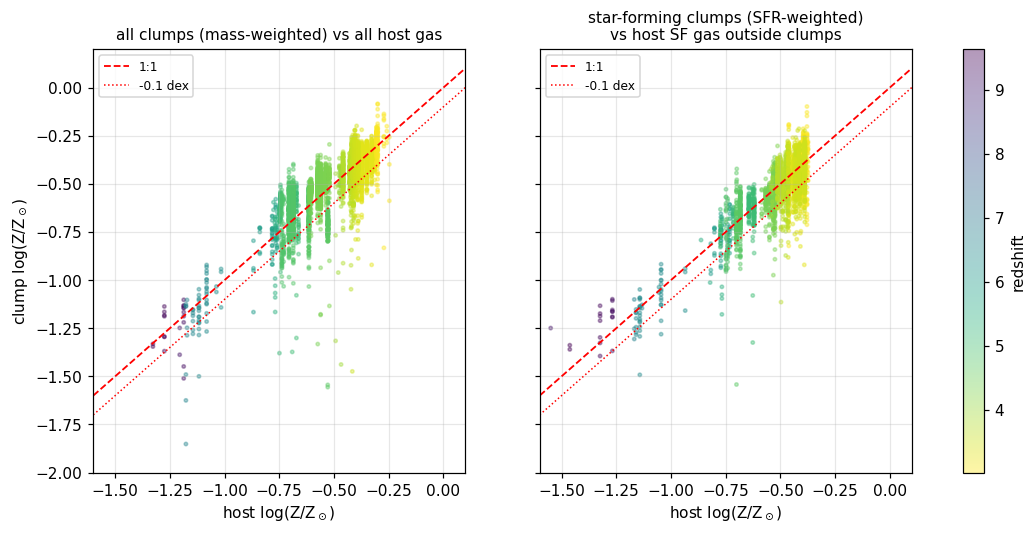

In [20]:
pc = clumps.join(snaps[["Z_sfrw_out"]], on=["Run", "Snapshot"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lims = [-1.6, 0.1]
panels = [("Z_all", "Z_Zsun", "all clumps (mass-weighted) vs all host gas", pc),
          ("Z_sfrw_out", "Z_sfr_Zsun", "star-forming clumps (SFR-weighted)\nvs host SF gas outside clumps",
           pc[pc["star_forming"]])]
for ax, (xcol, ycol, title, d) in zip(axes, panels):
    d = d[(d[xcol] > 0) & (d[ycol] > 0)]
    sc = ax.scatter(np.log10(d[xcol]), np.log10(d[ycol]), c=d["z"], s=5, alpha=0.4, cmap="viridis_r")
    ax.plot(lims, lims, "r--", lw=1.2, label="1:1")
    ax.plot(lims, np.array(lims) - 0.1, "r:", lw=1, label="-0.1 dex")
    ax.set_xlim(lims); ax.set_ylim(-2.0, 0.2)
    ax.set_xlabel(r"host log(Z/Z$_\odot$)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel(r"clump log(Z/Z$_\odot$)")
fig.colorbar(sc, ax=axes, label="redshift")
plt.show()

## 5. Which clumps are diluted?

Two different questions that the earlier version mixed up:

- **Scatter among clumps**: how far a clump sits from the *other clumps* of the same galaxy at the same time. This says nothing about the host.
- **Dilution relative to the host**: Δ12+log(O/H) against the host's star-forming gas outside the clumps, using the same −0.1 dex threshold as the observations. Only star-forming clumps have an emission-line-like O/H, so only they enter.


In [21]:
clumps["dOH_vs_snapshot"] = clumps["OH"] - clumps.groupby(["Run", "Snapshot"])["OH"].transform("median")
multi = clumps.groupby(["Run", "Snapshot"])["OH"].transform("size") >= 5
s = clumps.loc[multi, "dOH_vs_snapshot"]
print("scatter among clumps of the same snapshot (snapshots with >= 5 clumps):")
print("  16th-84th percentile: %+.3f to %+.3f dex;  %.1f%% sit > 0.1 dex below their snapshot median\n"
      % (s.quantile(0.16), s.quantile(0.84), 100 * (s < -0.1).mean()))

sfc = clumps[clumps["star_forming"]].join(snaps[["OH_sfrw_out"]], on=["Run", "Snapshot"])
sfc = sfc[sfc["OH_sfrw_out"].notna()].copy()
sfc["dOH_host"] = sfc["OH_sfr"] - sfc["OH_sfrw_out"]
sfc["diluted"] = sfc["dOH_host"] <= -0.1
print("star-forming clumps vs host SF gas outside clumps: %d clumps in %d snapshots"
      % (len(sfc), sfc[["Run", "Snapshot"]].drop_duplicates().shape[0]))
print("  median offset %+.3f dex;  diluted (<= -0.1 dex): %d (%.1f%%)"
      % (sfc["dOH_host"].median(), sfc["diluted"].sum(), 100 * sfc["diluted"].mean()))
# fraction per snapshot, so a few clump-rich snapshots cannot dominate
fd = sfc.groupby(["Run", "Snapshot"])["diluted"].mean()
print("  per snapshot: median %.1f%% diluted (16-84%%: %.1f%% - %.1f%%)"
      % tuple(100 * fd.quantile([0.5, 0.16, 0.84])))

scatter among clumps of the same snapshot (snapshots with >= 5 clumps):
  16th-84th percentile: -0.070 to +0.060 dex;  9.8% sit > 0.1 dex below their snapshot median

star-forming clumps vs host SF gas outside clumps: 2941 clumps in 72 snapshots
  median offset +0.011 dex;  diluted (<= -0.1 dex): 328 (11.2%)
  per snapshot: median 8.5% diluted (16-84%: 0.0% - 18.4%)


median properties, diluted vs not (star-forming clumps)


diluted,False,True
M_gas [Msun],783096.062,940012.781
SFR_inst [Msun/yr],0.044,0.067
virial parameter,9.412,10.223
Sigma_gas [Msun/pc^2],249.268,269.753
d / R200c,0.040,0.038
R_eff [pc],32.155,34.252


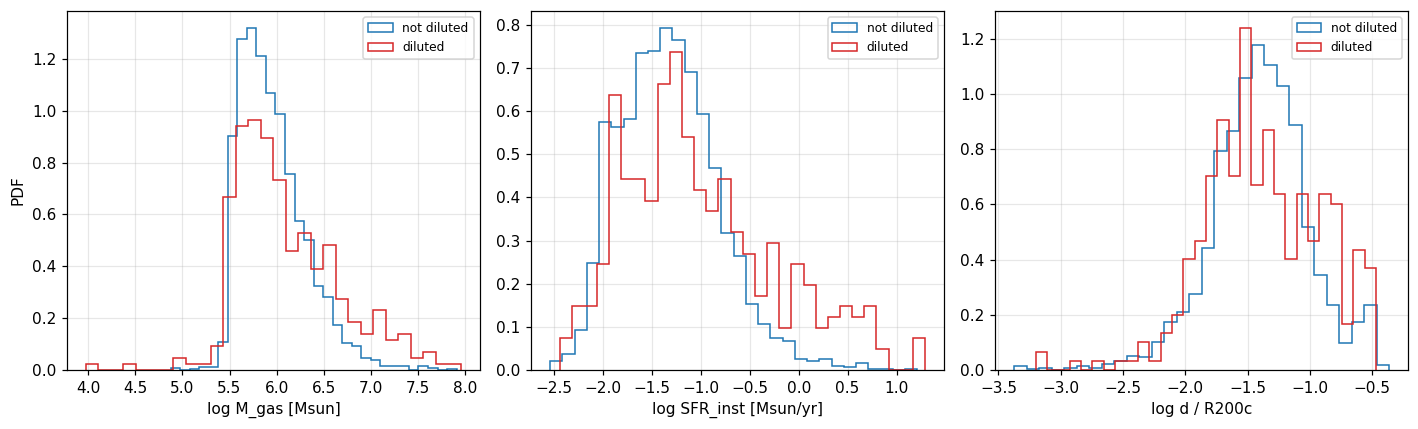

In [22]:
props = {"GasMass": "M_gas [Msun]", "sfr_inst": "SFR_inst [Msun/yr]", "alpha": "virial parameter",
         "Sigma_gas": "Sigma_gas [Msun/pc^2]", "x": "d / R200c", "R_eff_pc": "R_eff [pc]"}
print("median properties, diluted vs not (star-forming clumps)")
display(sfc.groupby("diluted")[list(props)].median().rename(columns=props).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["GasMass", "sfr_inst", "x"]):
    for flag, colr, lab in [(False, "C0", "not diluted"), (True, "C3", "diluted")]:
        v = sfc.loc[sfc["diluted"] == flag, col]
        ax.hist(np.log10(v[v > 0]), bins=30, histtype="step", density=True, color=colr, lw=1.5, label=lab)
    ax.set_xlabel("log " + props[col]); ax.legend(fontsize=8)
axes[0].set_ylabel("PDF")
plt.tight_layout(); plt.show()

## 6. Radial trend at fixed redshift

Distance is `|CenterPosition|`, normalised by R₂₀₀c from the tree. Metallicity rises with time, so pooling redshifts would turn that time evolution into a fake radial trend; each curve below is one redshift bin.


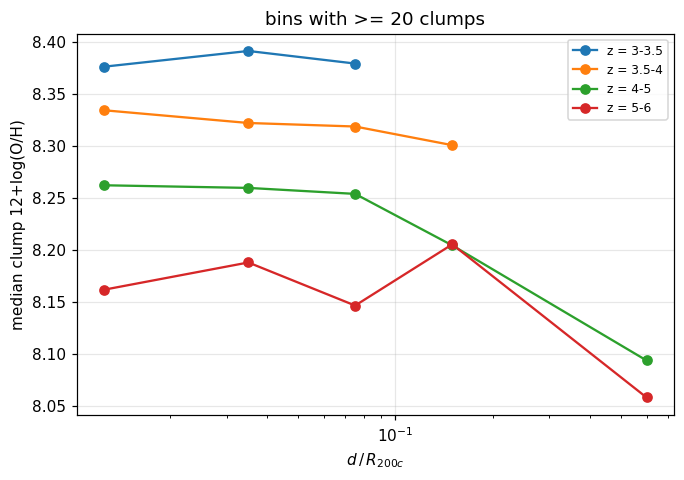

In [23]:
edges = [0.005, 0.02, 0.05, 0.1, 0.2, 1.0]
fig, ax = plt.subplots(figsize=(7, 4.5))
for lo, hi in [(3, 3.5), (3.5, 4), (4, 5), (5, 6)]:
    d = clumps[clumps["z"].between(lo, hi)]
    g = d.groupby(pd.cut(d["x"], edges), observed=True)["OH"]
    med, n = g.median(), g.size()
    keep_bins = n >= 20
    if keep_bins.sum() >= 2:
        ax.plot([iv.mid for iv in med.index[keep_bins]], med[keep_bins], "o-", label=f"z = {lo}-{hi}")
ax.set_xscale("log")
ax.set_xlabel(r"$d\,/\,R_{200c}$")
ax.set_ylabel("median clump 12+log(O/H)")
ax.set_title("bins with >= 20 clumps")
ax.legend(fontsize=8)
plt.show()

## 7. What correlates with a clump's metallicity?

This replaces the earlier all-column correlation matrix and the `correlation_*.py` plots. Those pooled z = 15 → 3, so every correlation was mostly time evolution, and the top pairs were bookkeeping: `SFR_yso` is exactly `StellarMass/3000` (r = 1), each element tracks its own `_sfr` version, and the elements track each other.

Here the metallicity is measured relative to the median clump of the same snapshot, which removes time evolution and does not depend on any host definition. Spearman rank correlation is used so the many clumps with zero SFR or zero young stars are kept (as ties) rather than dropped by a log axis.


In [24]:
cols = {"GasMass": "gas mass", "StellarMass": "young-star mass (< 3 Myr)", "sfr_inst": "SFR_inst",
        "alpha": "virial parameter", "R_eff_pc": "effective radius", "Sigma_gas": "gas surface density",
        "n_H": "mean density", "x": "d / R200c"}
d = clumps[multi]
rows = []
for col, lab in cols.items():
    rho, p = spearmanr(d[col], d["dOH_vs_snapshot"])
    rows.append({"property": lab, "Spearman rho": rho, "p": p,
                 "zeros kept": int((d[col] == 0).sum())})
pd.DataFrame(rows).set_index("property").round(4)

,Spearman rho,p,zeros kept
property,,,
gas mass,-0.0409,0.0084,0
young-star mass (< 3 Myr),-0.0750,0.0000,710
SFR_inst,0.0150,0.3326,930
virial parameter,0.0927,0.0000,0
effective radius,-0.0459,0.0031,0
gas surface density,0.0005,0.9745,0
mean density,0.0361,0.0201,0
d / R200c,-0.0640,0.0000,0


## 8. Other catalogs

The 8× and 16× catalogs (`gmc_output_z8.hdf5`, `gmc_output_z16.hdf5`) are higher-*resolution* runs of different targets, not higher redshifts. None of their targets has a host tree here yet, so the host comparison above can't be made for them. Within-snapshot clump scatter needs no host, so it can be compared across resolution now:


In [25]:
rows = []
for res in [4, 8, 16]:
    c = tz_gmc.load(res=res, variant="fiducial", resolved_only=True)
    c["OH"] = oh12(c["O_Fraction"], c["H_Fraction"])
    grp = c.groupby(["Run", "Snapshot", "HaloID"])["OH"]
    big = grp.transform("size") >= 5
    dev = (c["OH"] - grp.transform("median"))[big]
    rows.append({"resolution": f"{res}x", "clumps": int(big.sum()), "z range": "%.1f - %.1f" % (c["z"].min(), c["z"].max()),
                 "16th pct": dev.quantile(0.16), "84th pct": dev.quantile(0.84),
                 "% > 0.1 dex below median": 100 * (dev < -0.1).mean()})
pd.DataFrame(rows).set_index("resolution").round(3)

,clumps,z range,16th pct,84th pct,% > 0.1 dex below median
resolution,,,,,
4x,28819,3.0 - 15.1,-0.084,0.067,13.189
8x,27077,3.0 - 9.2,-0.104,0.077,16.715
16x,1443,3.1 - 3.5,-0.176,0.061,20.097
